# Ayudantía N°5:
### **Análisis de datos categóricos* en gráficos con `ggplot`*

Recordemos:
- Análisis univariado: Distribución de frecuencia: Tablas de frecuencia
- Análisis bivariado: Cruce de variables: Tablas de contingencia

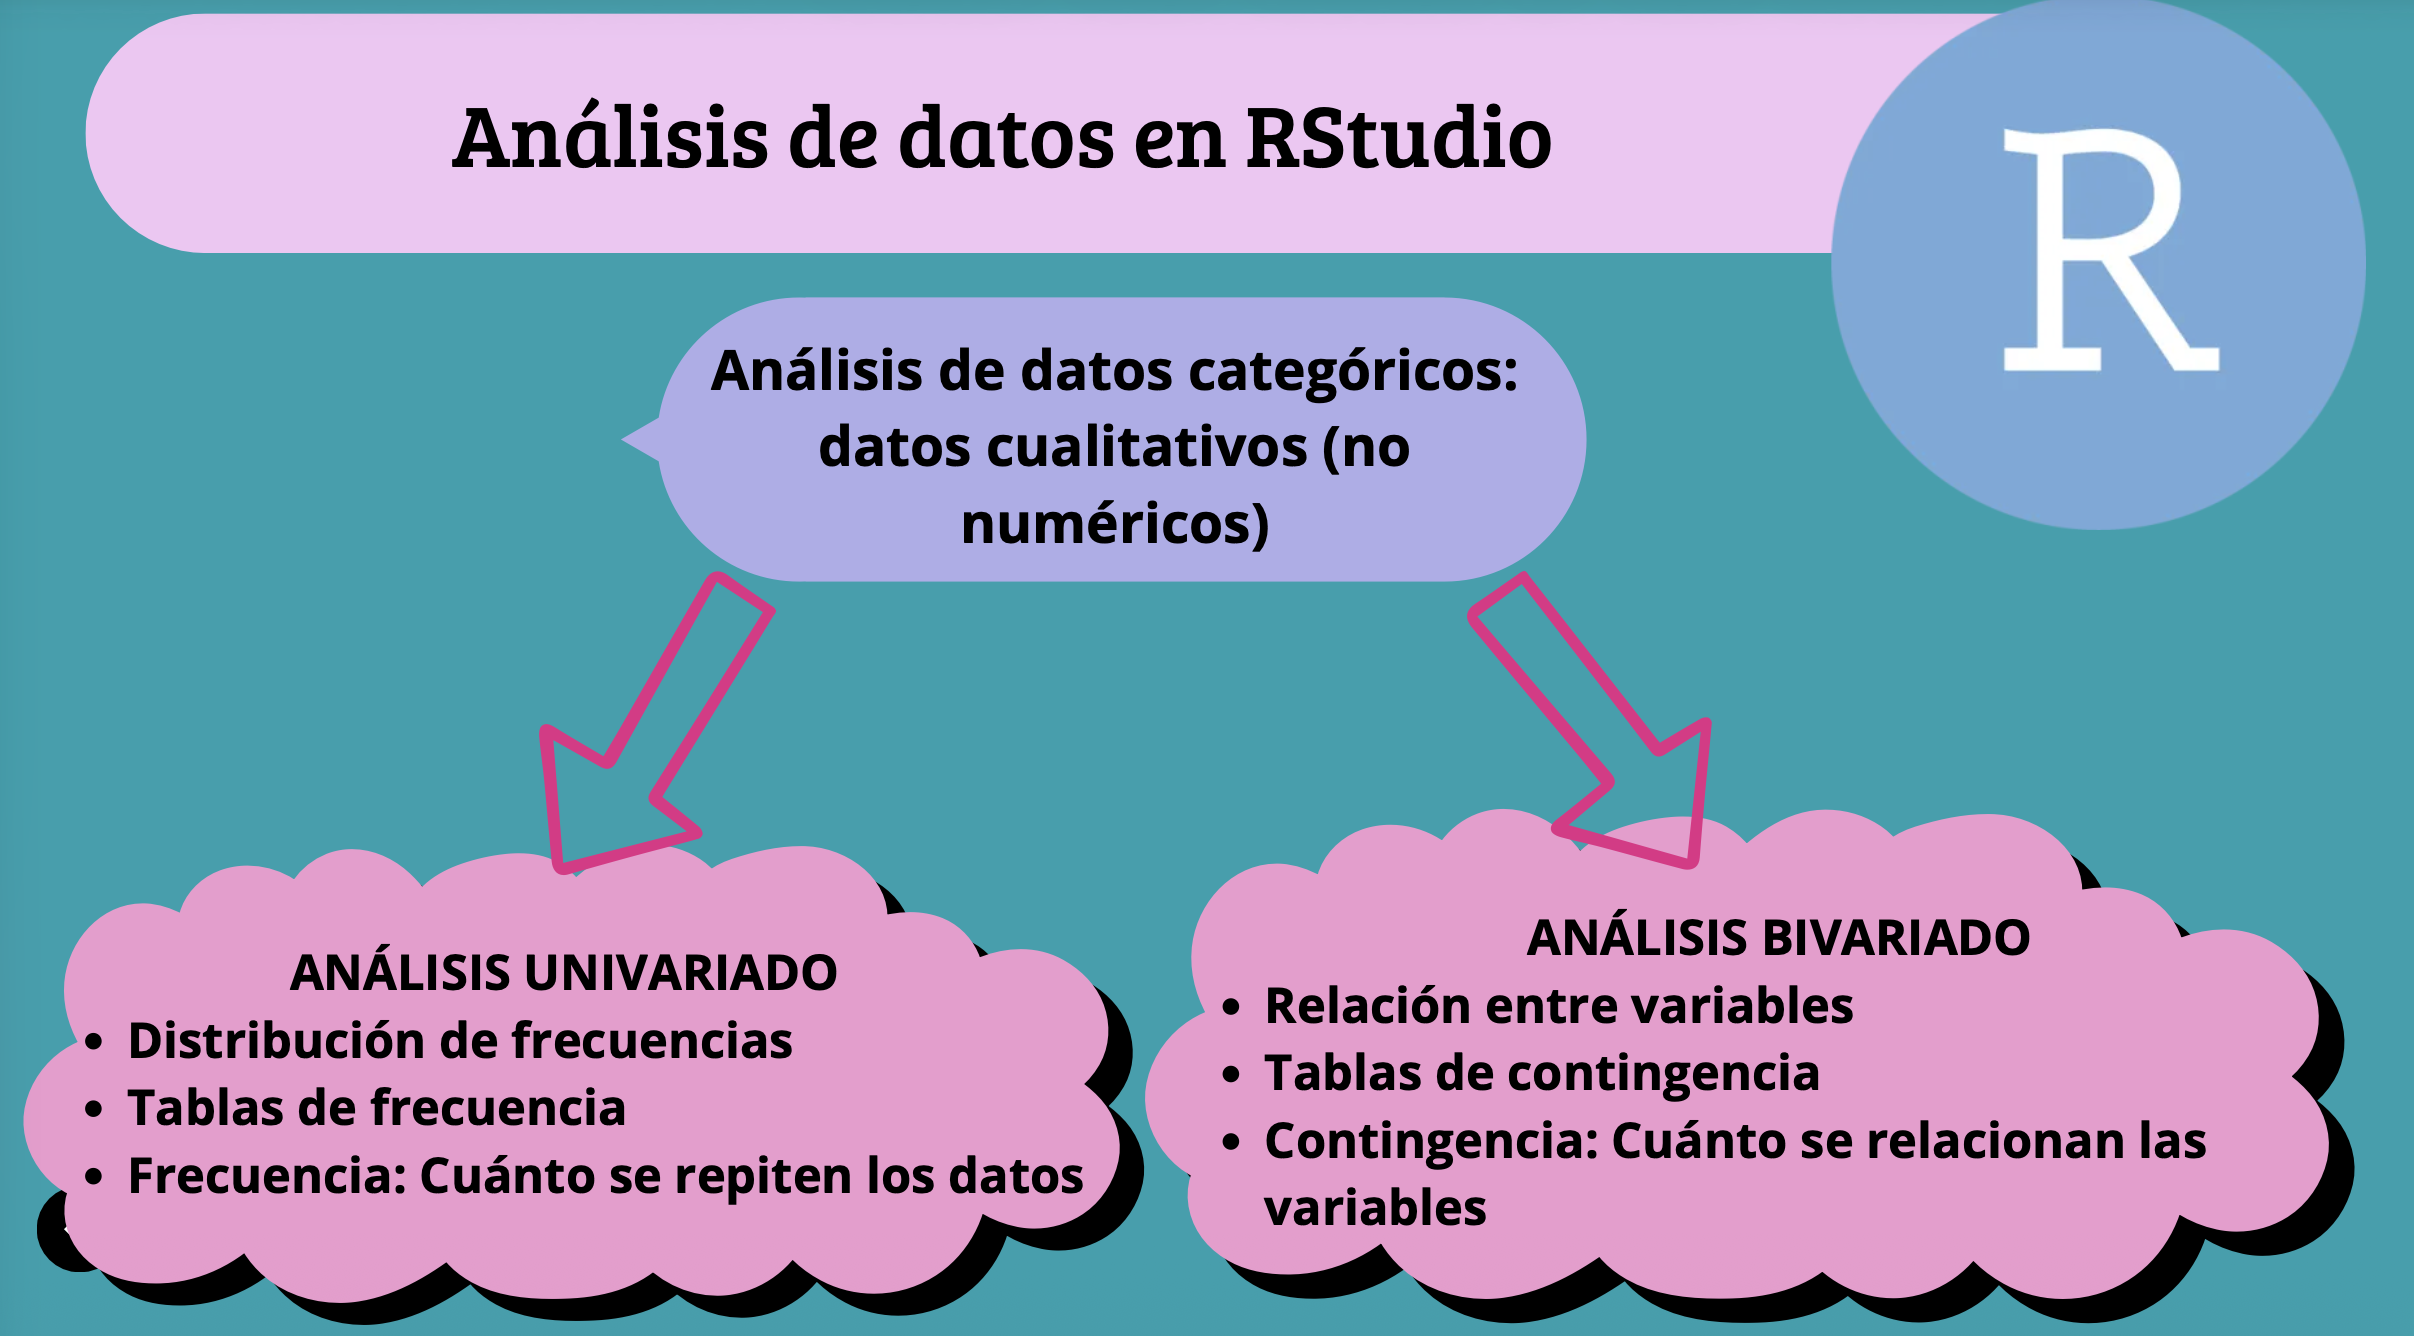

Utilizaremos la bbdd `base_antropologia_limpia.xlsx`

**Ruta de trabajo:** explorar datos → elegir variables → calcular frecuencias y porcentajes → graficar → modificar → interpretar críticamente

### Antes de comenzar: entorno R en Google Colab

1. Abre este cuaderno en Google Colab y selecciona **R** como entorno de ejecución
2. Sube el archivo **`base_antropologia_limpia.xlsx`** desde el panel **Archivos**
3. Ejecuta las celdas en orden. La importación se realiza directamente con `openxlsx::read.xlsx()`, tal como en la Ayudantía 6



In [1]:
# Cargar paquetes
if (!requireNamespace("pacman", quietly = TRUE)) install.packages("pacman", repos = "https://cloud.r-project.org")
pacman::p_load(tidyverse, openxlsx, scales)


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘remotes’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)


openxlsx installed



In [ ]:
# Importar directamente la base de datos
base <- read.xlsx("content/base_antropologia_limpia.xlsx")

# Explorar la base antes de analizarla
glimpse(base)
str(base)
summary(base)
names(base)


## 1. Reconocer las categorías antes de dibujar

Un gráfico de categorías no empieza en `ggplot()`, sino preguntándonos **qué variable representa cada respuesta** y **cuántos casos válidos tiene**. Aquí hay variables nominales (por ejemplo, identidad de género), ordinales (carga académica, satisfacción) y variables agrupadas (distancia al campus). No debemos interpretar sus categorías como números continuos.

**Práctica:** Ejecuta el código y responde: ¿qué variable tiene categorías que expresan un orden? ¿Cuál permite describir diferencias entre grupos, pero no ordenarlos?

In [ ]:
# Explorar directamente las categorías de las variables que usaremos
table(base$comuna_distancia, useNA = "ifany")
table(base$to_01, useNA = "ifany")
table(base$ea_03_descripcion_carga_academica, useNA = "ifany")
table(base$ea_05_satisfaccion_rendimiento_academico_r, useNA = "ifany")
table(base$ea_06_nivel_estres_ultimo_semestre_r, useNA = "ifany")


**Mini desafío: leer el código.** En `table(base$identidad_genero_r, useNA = "ifany")`, identifica el objeto que contiene la base, la variable analizada y el argumento que permite observar los valores ausentes


In [ ]:
#¿Qué hace esta función? ¿Cuál es la función y qué componentes contiene?
table(base$identidad_genero_r, useNA = "ifany")

# **Gráficos con ggplot**

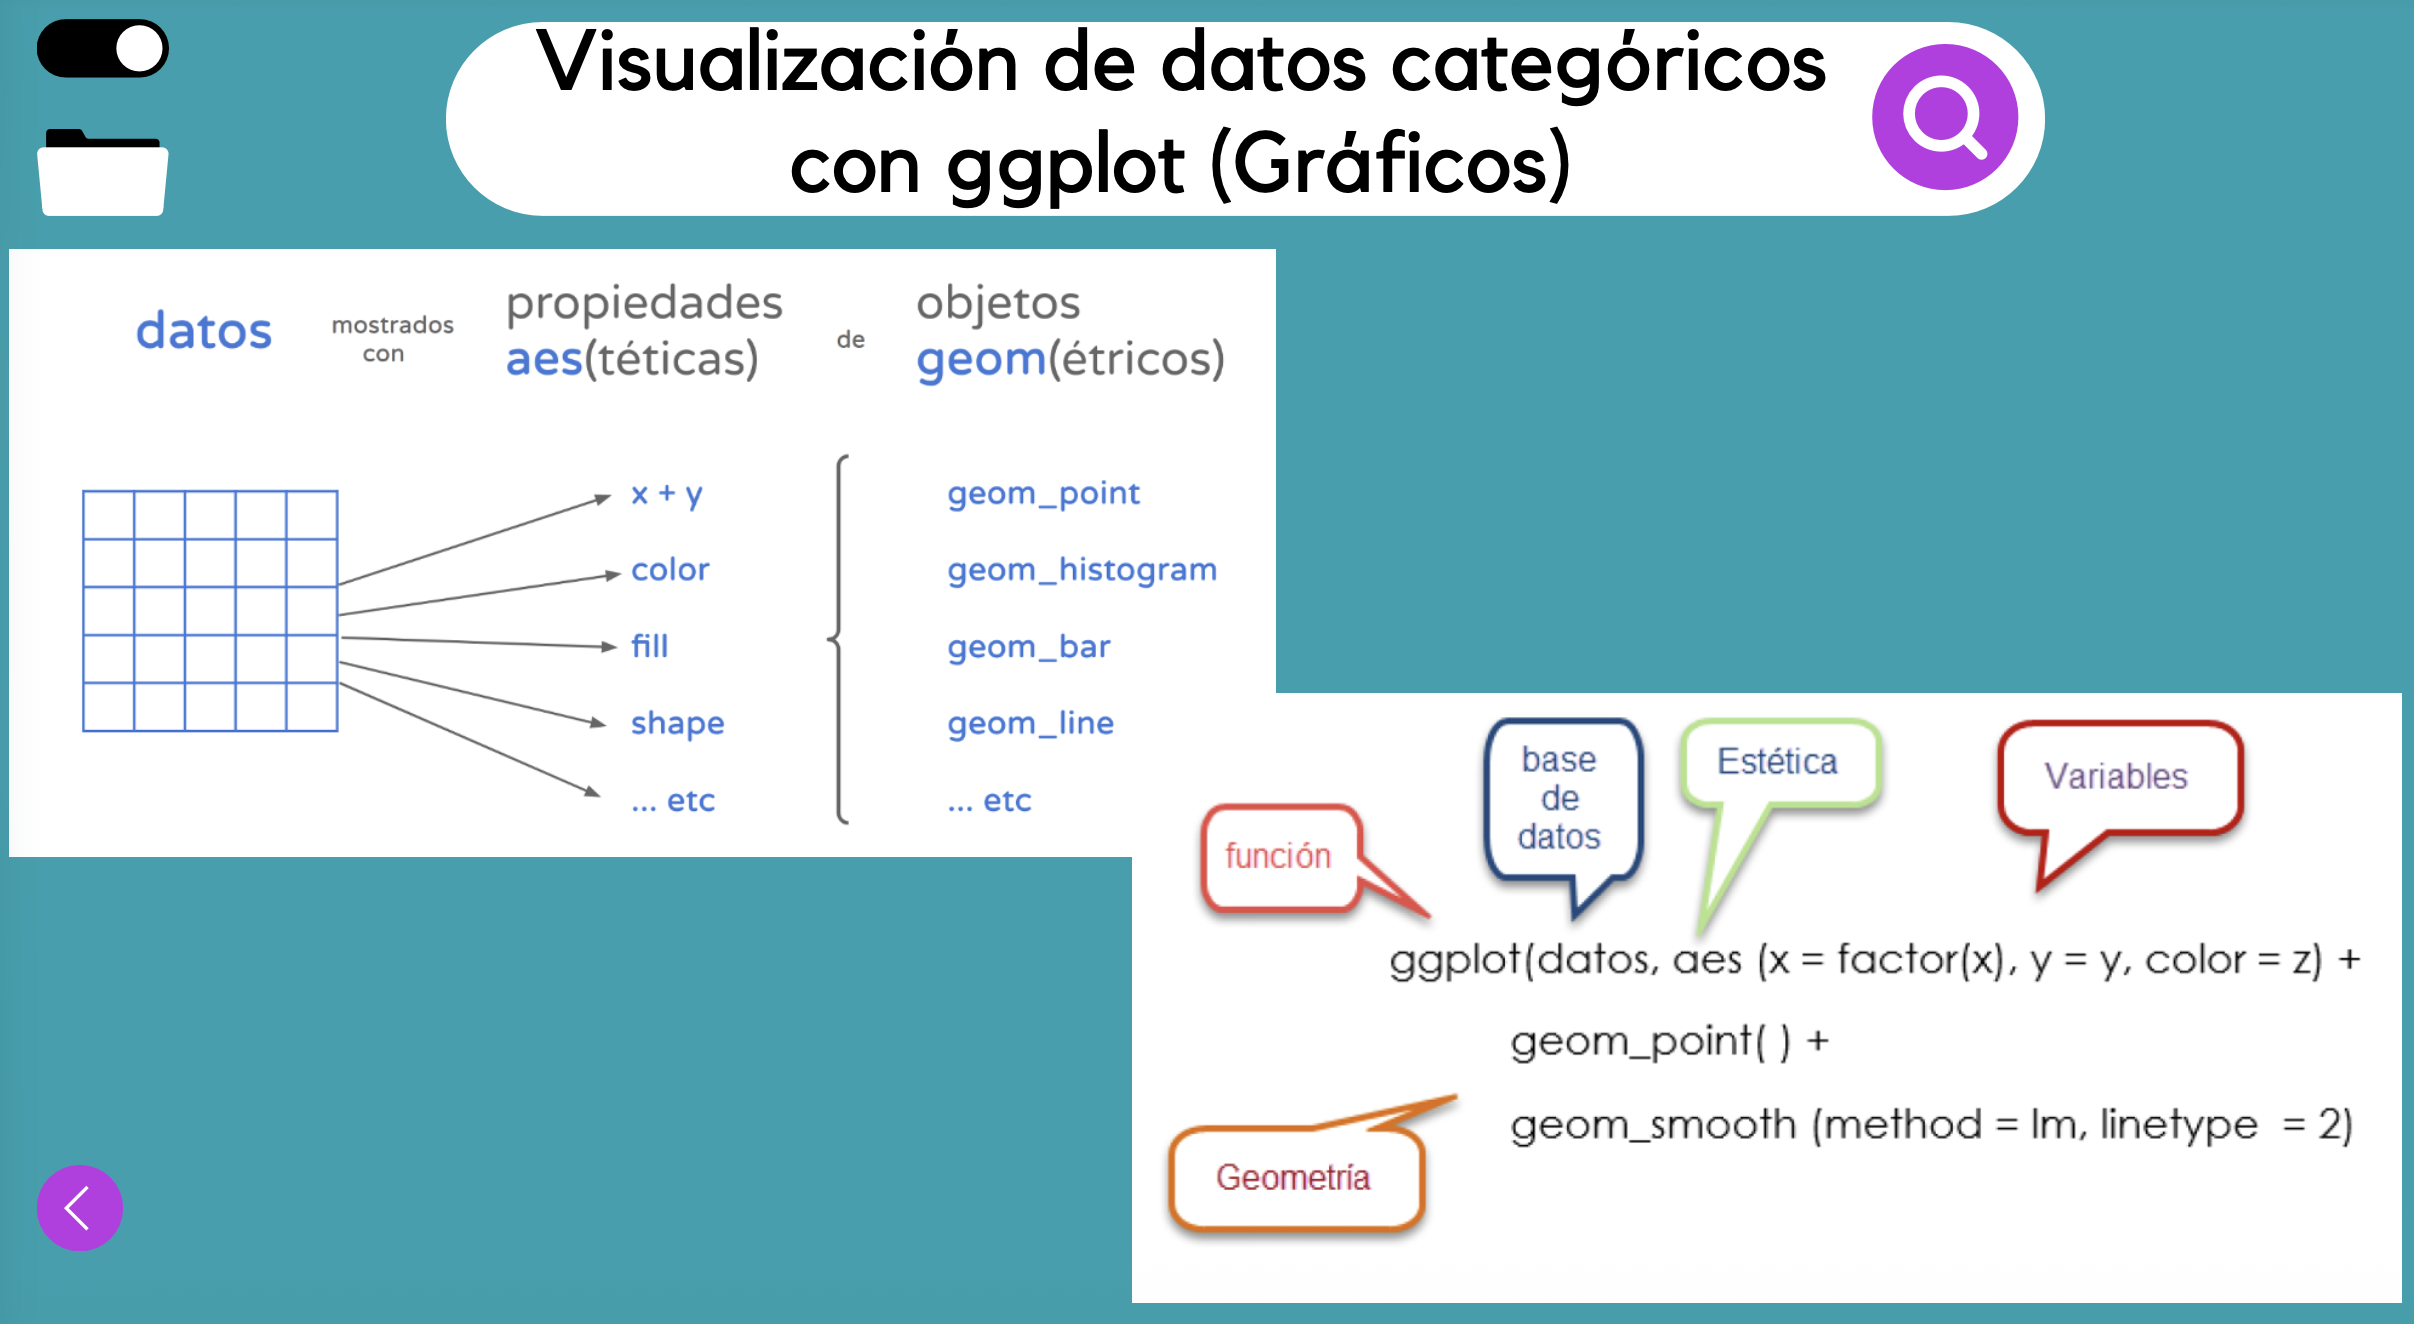

## 1. Primer gráfico: ¿cómo se percibe la carga académica?

Usaremos `ea_03_descripcion_carga_academica`, que contiene exactamente estas categorías: **Moderada, Pesada, Ligera y Muy pesada**

In [ ]:
# Vemos sus categorías
unique(base$ea_03_descripcion_carga_academica)

In [ ]:
# Construimos la tabla que alimentará el gráfico
tabla_carga <- base %>%
  count(ea_03_descripcion_carga_academica, name = "n") %>%
  mutate(porcentaje = 100 * n / sum(n))
tabla_carga

# geom_col() usa la columna n ya calculada
ggplot(tabla_carga, aes(x = ea_03_descripcion_carga_academica, y = n)) +
  geom_col(fill = "steelblue") +
  labs(title = "Percepción de la carga académica",
       x = "Carga académica percibida", y = "Número de estudiantes") +
  theme_minimal()

**Práctica:** Sustituye `"steelblue"` por `"darkorange"` y después por `"seagreen"`. Cambia el título por una pregunta de investigación

In [ ]:
ggplot(tabla_carga, aes(x = ea_03_descripcion_carga_academica, y = n)) +
  geom_col(fill = "steelblue") +
  labs(title = "Percepción de la carga académica",
       x = "Carga académica percibida", y = "Número de estudiantes") +
  theme_minimal()

¿Qué cambia en la representación y qué permanece igual? ¿Cuál categoría es la más frecuente? ¿Es correcto decir que la carga académica *causa* estrés a partir de este gráfico?

## 2. Hacer un gráfico más legible: ordenar y etiquetar

Para comparar categorías conviene ordenar las barras según su frecuencia. Aquí **solo cambia la presentación visual**; las respuestas originales permanecen intactas.

In [ ]:
ggplot(tabla_carga,
       aes(x = fct_reorder(ea_03_descripcion_carga_academica, n), y = n)) +
  geom_col(fill = "mediumpurple4", width = 0.7) +
  geom_text(aes(label = paste0(round(porcentaje, 1), "%")),
            hjust = -0.1, size = 4) +
  coord_flip() +
  expand_limits(y = max(tabla_carga$n) * 1.17) +
  labs(title = "Carga académica: frecuencias y porcentajes",
       x = "Percepción de carga", y = "Estudiantes") +
  theme_minimal()

**Práctica:** Identifica qué hacen `fct_reorder()`, `coord_flip()` y `geom_text()`. Luego modifica `size = 4` a `size = 3` y cambia el color de las barras. ¿Qué versión permite leer mejor los nombres de las categorías? ¿Por qué?

In [ ]:
ggplot(tabla_carga,
       aes(x = fct_reorder(ea_03_descripcion_carga_academica, n),
           y = n)) +
  geom_col(fill = "coral3", width = 0.7) +
  geom_text(aes(label = paste0(round(porcentaje, 1), "%")),
            hjust = -0.1,
            size = 3) +
  coord_flip() +
  expand_limits(y = max(tabla_carga$n) * 1.17) +
  labs(title = "Distribución de la carga académica",
       x = "Carga académica",
       y = "Número de estudiantes") +
  theme_classic()

- fct_reorder(..., n)	Ordena las categorías según sus frecuencias
- coord_flip()	Intercambia los ejes para mostrar barras horizontales
- geom_text()	Añade las etiquetas con porcentajes
- size = 3	Reduce el tamaño de las etiquetas
- width = 0.7	Ajusta el grosor de las barras
- theme_classic()	Cambia la apariencia general del gráfico

## 3. Dos variables: carga académica y satisfacción con el rendimiento

**¿La distribución de satisfacción académica es similar entre quienes perciben una carga ligera, moderada, pesada o muy pesada?**

Usaremos `ea_05_satisfaccion_rendimiento_academico_r`, con categorías observadas **Satisfecho** e **Insatisfecho**

In [ ]:
# Tabla de contingencia: solo respuestas válidas para ambas variables
tabla_cruce <- base %>%
  filter(!is.na(ea_03_descripcion_carga_academica),
         !is.na(ea_05_satisfaccion_rendimiento_academico_r)) %>%
  count(ea_03_descripcion_carga_academica,
        ea_05_satisfaccion_rendimiento_academico_r, name = "n") %>%
  group_by(ea_03_descripcion_carga_academica) %>%
  mutate(porcentaje_dentro_carga = 100 * n / sum(n)) %>%
  ungroup()
tabla_cruce

In [ ]:
# Barras apiladas al 100%: comparamos proporciones dentro de cada carga
ggplot(tabla_cruce,
       aes(x = ea_03_descripcion_carga_academica,
           y = porcentaje_dentro_carga,
           fill = ea_05_satisfaccion_rendimiento_academico_r)) +
  geom_col(width = 0.75) +
  scale_fill_brewer(palette = "Set2") +
  scale_y_continuous(labels = label_percent(scale = 1)) +
  labs(title = "Satisfacción según percepción de carga académica",
       x = "Carga académica", y = "Porcentaje dentro de cada grupo",
       fill = "Satisfacción") +
  theme_minimal()

**Práctica: colores y lectura de porcentajes.** Cambia `palette = "Set2"` por `palette = "Pastel1"` y después por `palette = "Dark2"`. ¿Qué cambia en la visualización? ¿Cambian los porcentajes? Explica la diferencia entre cambiar la apariencia de un gráfico y modificar los datos


## 4. Añadir etiquetas a un gráfico de porcentajes

Las etiquetas facilitan la lectura, pero pueden saturar gráficos con muchos segmentos. La decisión de incluirlas también es una decisión de comunicación de resultados

In [ ]:
ggplot(tabla_cruce,
       aes(x = ea_03_descripcion_carga_academica,
           y = porcentaje_dentro_carga,
           fill = ea_05_satisfaccion_rendimiento_academico_r)) +
  geom_col() +
  geom_text(aes(label = paste0(round(porcentaje_dentro_carga, 1), "%")),
            position = position_stack(vjust = 0.5), color = "white", size = 3.5) +
  scale_fill_brewer(palette = "Set2") +
  labs(title = "Satisfacción académica según carga percibida",
       x = "Carga académica", y = "Porcentaje dentro de cada grupo",
       fill = "Satisfacción") +
  theme_minimal()

**Práctica:** Cambia `size = 3.5` por `size = 5`. ¿Se superponen las etiquetas? Prueba `coord_flip()` al final del código. ¿Mejora la legibilidad? Interpretemos utilizando el denominador: *entre quienes perciben una carga...*

In [ ]:
ggplot(tabla_cruce,
       aes(x = ea_03_descripcion_carga_academica,
           y = porcentaje_dentro_carga,
           fill = ea_05_satisfaccion_rendimiento_academico_r)) +
  geom_col() +
  geom_text(
    aes(label = paste0(round(porcentaje_dentro_carga, 1), "%")),
    position = position_stack(vjust = 0.5),
    color = "black",
    size = 5
  ) +
  scale_fill_brewer(palette = "Pastel1") +
  coord_flip() +
  labs(title = "Satisfacción académica según carga percibida",
       x = "Carga académica",
       y = "Porcentaje dentro de cada grupo",
       fill = "Satisfacción") +
  theme_minimal()

## 5. Otra pregunta: distancia de residencia y estrés académico

Ahora analizaremos `comuna_distancia` y `ea_06_nivel_estres_ultimo_semestre_r`. La primera contiene **Vive muy cerca, Vive a distancia cercana, Vive a distancia media, Vive a mucha distancia y Fuera de Santiago**. La segunda contiene **Estres Bajo, Estres Moderado y Estres Alto**

**Precaución analítica:** no podemos asumir que la distancia explica el estrés; también intervienen otras condiciones no controladas aquí. Además, algunos grupos pueden ser pequeños

In [ ]:
tabla_distancia <- base %>%
  filter(!is.na(comuna_distancia),
         !is.na(ea_06_nivel_estres_ultimo_semestre_r)) %>%
  count(comuna_distancia, ea_06_nivel_estres_ultimo_semestre_r,
        name = "n") %>%
  group_by(comuna_distancia) %>%
  mutate(pct = 100 * n / sum(n)) %>%
  ungroup()

ggplot(tabla_distancia,
       aes(x = comuna_distancia, y = pct,
           fill = ea_06_nivel_estres_ultimo_semestre_r)) +
  geom_col() +
  coord_flip() +
  scale_y_continuous(labels = label_percent(scale = 1)) +
  labs(title = "Nivel de estrés según distancia de residencia",
       x = "Distancia", y = "Porcentaje dentro de cada distancia",
       fill = "Nivel de estrés") +
  theme_minimal()

**Práctica:** Cambia `theme_minimal()` por `theme_classic()`. Prueba otra paleta con `scale_fill_brewer(palette = "Set3")`. Identifica si alguna categoría de distancia tiene pocos casos; ¿por qué debe advertirse esto al interpretar diferencias porcentuales?


In [ ]:
# Revisamos el tamaño de los grupos: indispensable para interpretar porcentajes
base %>%
  filter(!is.na(ea_06_nivel_estres_ultimo_semestre_r)) %>%
  count(comuna_distancia, name = "casos_validos") %>%
  arrange(casos_validos)

## 6. Gráficos de paneles (`facet_wrap`): tiempo de ocio y carga académica

Una tercera pregunta permite mirar la relación entre `to_01` (tiempo disponible para ocio) y `ea_03_descripcion_carga_academica`. Las respuestas de `to_01` son **Poco tiempo., Suficiente tiempo., Bastante tiempo. y No tengo tiempo.**. Los paneles permiten comparar distribuciones sin superponer todos los colores en un único gráfico.

In [ ]:
table(base$ea_03_descripcion_carga_academica)

In [ ]:
tabla_ocio <- base %>%
  count(to_01, ea_03_descripcion_carga_academica, name = "n") %>%
  group_by(to_01) %>%
  mutate(pct = 100 * n / sum(n)) %>%
  ungroup()

ggplot(tabla_ocio,
       aes(x = ea_03_descripcion_carga_academica, y = pct)) +
  geom_col(fill = "#4477AA") +
  facet_wrap(~ to_01) +
  coord_flip() +
  labs(title = "Carga académica percibida por tiempo disponible para ocio",
       x = "Carga académica", y = "% dentro de cada grupo de ocio") +
  theme_minimal()

**Práctica:** Modifica `facet_wrap(~ to_01)` por `facet_wrap(~ to_01, ncol = 2)`. Cambia el color de las barras y el título. ¿Cómo cambia la lectura si comparamos porcentajes y no números de personas?

In [ ]:
ggplot(tabla_ocio,
       aes(x = ea_03_descripcion_carga_academica,
           y = pct)) +
  geom_col(fill = "darkorchid3") +
  facet_wrap(~ to_01, ncol = 2) +
  coord_flip() +
  labs(title = "Carga académica según tiempo disponible para ocio",
       x = "Carga académica percibida",
       y = "Porcentaje dentro del grupo") +
  theme_minimal()

## 7. Un gráfico diferente: puntos y segmentos (lollipop)

Cuando hay pocas categorías, un gráfico de puntos y segmentos puede ser una alternativa a las barras. Usaremos las frecuencias reales de `identidad_genero_r`: **Mujer cisgenero, Hombre cisgenero y Persona de genero diverso**. Son categorías de la base recodificada, no etiquetas creadas para esta actividad.

In [ ]:
tabla_genero <- base %>%
  count(identidad_genero_r, name = "n")

ggplot(tabla_genero,
       aes(x = fct_reorder(identidad_genero_r, n), y = n)) +
  geom_segment(aes(xend = identidad_genero_r, y = 0, yend = n),
               linewidth = 1.2, color = "grey60") +
  geom_point(size = 5, color = "#CC6677") +
  coord_flip() +
  labs(title = "Identidad de género (categorías recodificadas)",
       x = "Identidad de género", y = "Número de estudiantes") +
  theme_minimal()

**Práctica:** Cambia `size = 5` por `size = 3` y luego el color de los puntos. ¿Qué aporta el gráfico de puntos frente a un gráfico de barras? ¿Por qué es importante mencionar que estamos trabajando con una variable *recodificada* y no con las ocho categorías de `identidad_genero`?

In [ ]:
ggplot(tabla_genero,
       aes(x = fct_reorder(identidad_genero_r, n),
           y = n)) +
  geom_segment(
    aes(xend = identidad_genero_r, y = 0, yend = n),
    linewidth = 1.2,
    color = "grey60"
  ) +
  geom_point(size = 3, color = "darkorange") +
  coord_flip() +
  labs(title = "Distribución de identidad de género",
       x = "Identidad de género",
       y = "Número de estudiantes") +
  theme_minimal()